# Sales Data Analysis
**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn

This project explores a sample retail dataset: data quality, KPIs, monthly trends, region/state performance, category/segment performance, and business recommendations.

> Note: `data/sales_data.csv` is synthetic demonstration data generated for this project. Replace it with an authorized real dataset before presenting findings as real business results.

## 1. Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)
pd.set_option('display.max_columns', None)

## 2. Load the dataset

In [3]:
from pathlib import Path

DATA_PATH = Path('../data/sales_data.csv')
if not DATA_PATH.exists():
    DATA_PATH = Path('data/sales_data.csv')  # fallback if notebook runs from project root
df = pd.read_csv(DATA_PATH)
df.head()

,Order ID,Order Date,Customer ID,Segment,Region,State,Category,Sub-Category,Sales,Quantity,Discount,Profit
0,ORD-00001,2019-03-07,CUST-0253,Corporate,East,Virginia,Technology,Machines,1179.51,4,0.15,178.63
1,ORD-00002,2020-07-19,CUST-0340,Consumer,East,Massachusetts,Office Supplies,Storage,135.08,3,0.00,25.23
2,ORD-00003,2020-04-23,CUST-0172,Corporate,West,Washington,Technology,Phones,2102.90,7,0.10,374.20
3,ORD-00004,2019-11-17,CUST-0324,Consumer,West,Washington,Technology,Copiers,520.00,2,0.00,59.56
4,ORD-00005,2019-11-13,CUST-0303,Corporate,Central,Wisconsin,Technology,Copiers,239.38,1,0.20,-11.01


## 3. Inspect data and quality

In [4]:
print('Rows, columns:', df.shape)
print('\nColumn types and non-null counts:')
df.info()
display(df.describe(include='all').T)
print('\nMissing values:')
display(df.isna().sum().to_frame('missing_count'))
print('\nDuplicate rows:', df.duplicated().sum())

Rows, columns: (1200, 12)

Column types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Order ID      1200 non-null   str    
 1   Order Date    1200 non-null   str    
 2   Customer ID   1200 non-null   str    
 3   Segment       1200 non-null   str    
 4   Region        1200 non-null   str    
 5   State         1200 non-null   str    
 6   Category      1200 non-null   str    
 7   Sub-Category  1200 non-null   str    
 8   Sales         1200 non-null   float64
 9   Quantity      1200 non-null   int64  
 10  Discount      1200 non-null   float64
 11  Profit        1200 non-null   float64
dtypes: float64(3), int64(1), str(8)
memory usage: 194.0 KB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Order ID,1200,1200,ORD-00001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Order Date,1200,579,2019-04-13,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer ID,1200,338,CUST-0079,9,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Segment,1200,3,Consumer,714,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Region,1200,4,West,386,NaN,NaN,NaN,NaN,NaN,NaN,NaN
State,1200,20,Colorado,86,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Category,1200,3,Office Supplies,595,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sub-Category,1200,13,Labels,129,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sales,1200.0,NaN,NaN,NaN,338.504675,363.003711,9.0,88.755,193.43,470.645,2102.9
Quantity,1200.0,NaN,NaN,NaN,4.05,2.005622,1.0,2.0,4.0,6.0,7.0



Missing values:


,missing_count
Order ID,0
Order Date,0
Customer ID,0
Segment,0
Region,0
State,0
Category,0
Sub-Category,0
Sales,0
Quantity,0



Duplicate rows: 0


## 4. Clean and prepare the data

In [5]:
df = df.drop_duplicates().copy()
df['Order Date'] = pd.to_datetime(df['Order Date'], errors='coerce')
for col in ['Sales', 'Profit', 'Quantity', 'Discount']:
    df[col] = pd.to_numeric(df[col], errors='coerce')
df = df.dropna(subset=['Order Date', 'Sales', 'Profit', 'Quantity'])
df = df[df['Sales'] >= 0].copy()
df['Year'] = df['Order Date'].dt.year
df['Month'] = df['Order Date'].dt.month
df['Month Name'] = df['Order Date'].dt.strftime('%b')
df['Year-Month'] = df['Order Date'].dt.to_period('M').astype(str)
print('Cleaned shape:', df.shape)
df.head()

Cleaned shape: (1200, 16)


,Order ID,Order Date,Customer ID,Segment,Region,State,Category,Sub-Category,Sales,Quantity,Discount,Profit,Year,Month,Month Name,Year-Month
0,ORD-00001,2019-03-07,CUST-0253,Corporate,East,Virginia,Technology,Machines,1179.51,4,0.15,178.63,2019,3,Mar,2019-03
1,ORD-00002,2020-07-19,CUST-0340,Consumer,East,Massachusetts,Office Supplies,Storage,135.08,3,0.00,25.23,2020,7,Jul,2020-07
2,ORD-00003,2020-04-23,CUST-0172,Corporate,West,Washington,Technology,Phones,2102.90,7,0.10,374.20,2020,4,Apr,2020-04
3,ORD-00004,2019-11-17,CUST-0324,Consumer,West,Washington,Technology,Copiers,520.00,2,0.00,59.56,2019,11,Nov,2019-11
4,ORD-00005,2019-11-13,CUST-0303,Corporate,Central,Wisconsin,Technology,Copiers,239.38,1,0.20,-11.01,2019,11,Nov,2019-11


## 5. Key performance indicators (KPIs)

In [6]:
total_orders = df['Order ID'].nunique()
total_customers = df['Customer ID'].nunique()
total_sales = df['Sales'].sum()
total_profit = df['Profit'].sum()
total_discount = (df['Sales'] * df['Discount']).sum()
total_quantity = df['Quantity'].sum()
profit_margin = (total_profit / total_sales * 100) if total_sales else 0

kpis = pd.Series({
    'Total Orders': total_orders,
    'Unique Customers': total_customers,
    'Total Sales': round(total_sales, 2),
    'Total Profit': round(total_profit, 2),
    'Estimated Discount Value': round(total_discount, 2),
    'Total Quantity': total_quantity,
    'Profit Margin (%)': round(profit_margin, 2)
})
display(kpis.to_frame('Value'))

,Value
Total Orders,1200.00
Unique Customers,338.00
Total Sales,406205.61
Total Profit,30633.45
Estimated Discount Value,41715.94
Total Quantity,4860.00
Profit Margin (%),7.54


## 6. Monthly sales and profit trend

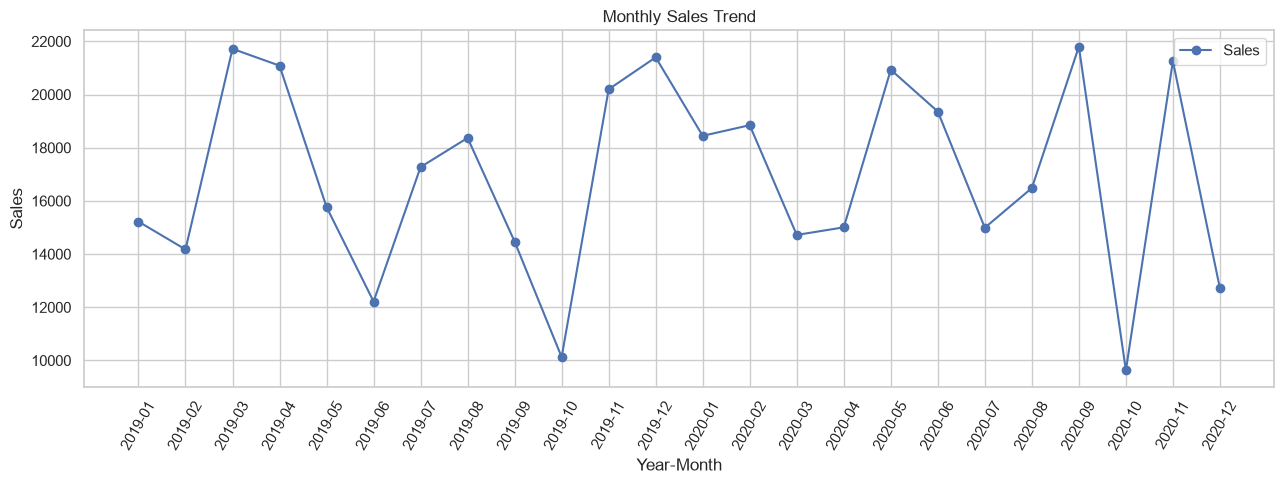

,Year-Month,Sales,Profit
20,2020-09,21800.50,1315.90
2,2019-03,21718.41,1763.04
11,2019-12,21398.96,1501.53
22,2020-11,21257.64,1722.60
3,2019-04,21086.12,2049.28


In [7]:
monthly = df.groupby('Year-Month', as_index=False).agg(Sales=('Sales','sum'), Profit=('Profit','sum'))
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(monthly['Year-Month'], monthly['Sales'], marker='o', label='Sales')
ax.set_title('Monthly Sales Trend')
ax.set_xlabel('Year-Month')
ax.set_ylabel('Sales')
ax.tick_params(axis='x', rotation=60)
ax.legend()
plt.tight_layout()
plt.show()

monthly.sort_values('Sales', ascending=False).head(5)

## 7. Sales by region and state

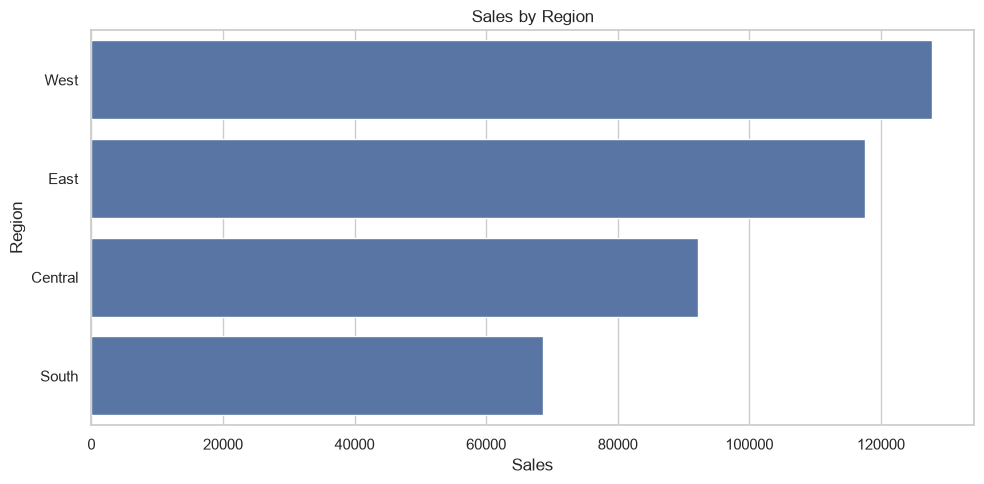

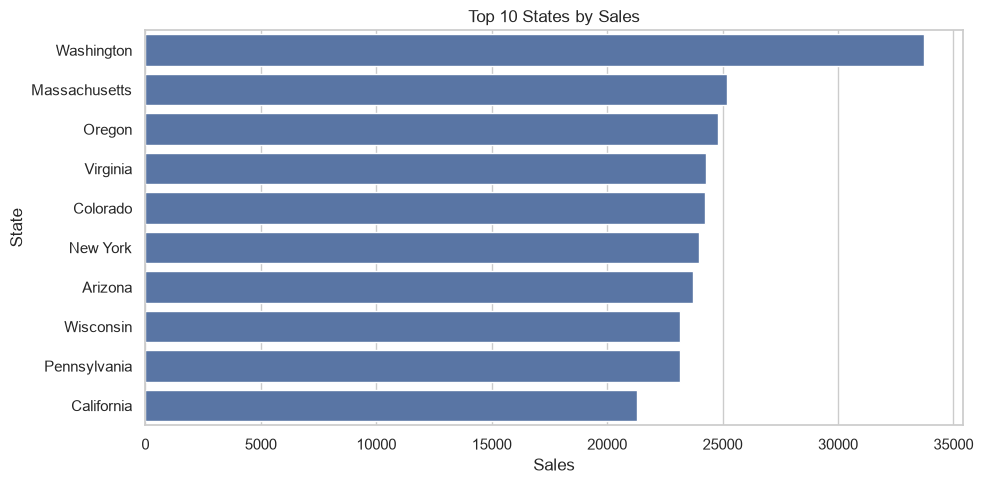

,Region,Sales
3,West,127762.78
1,East,117589.68
0,Central,92152.94
2,South,68700.21


,State,Sales
18,Washington,33734.16
7,Massachusetts,25180.47
13,Oregon,24793.46
17,Virginia,24259.95
3,Colorado,24221.21
10,New York,23985.61
1,Arizona,23724.97
19,Wisconsin,23157.14
14,Pennsylvania,23151.28
2,California,21288.98


In [8]:
region_sales = df.groupby('Region', as_index=False)['Sales'].sum().sort_values('Sales', ascending=False)
sns.barplot(data=region_sales, x='Sales', y='Region')
plt.title('Sales by Region')
plt.tight_layout()
plt.show()

state_sales = df.groupby('State', as_index=False)['Sales'].sum().sort_values('Sales', ascending=False)
sns.barplot(data=state_sales.head(10), x='Sales', y='State')
plt.title('Top 10 States by Sales')
plt.tight_layout()
plt.show()
display(region_sales)
display(state_sales.head(10))

## 8. Category, sub-category and segment analysis

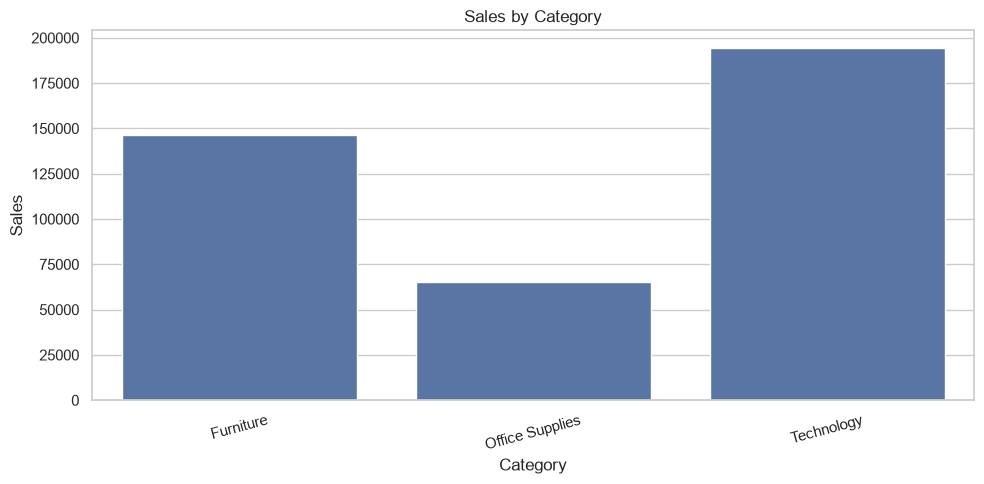

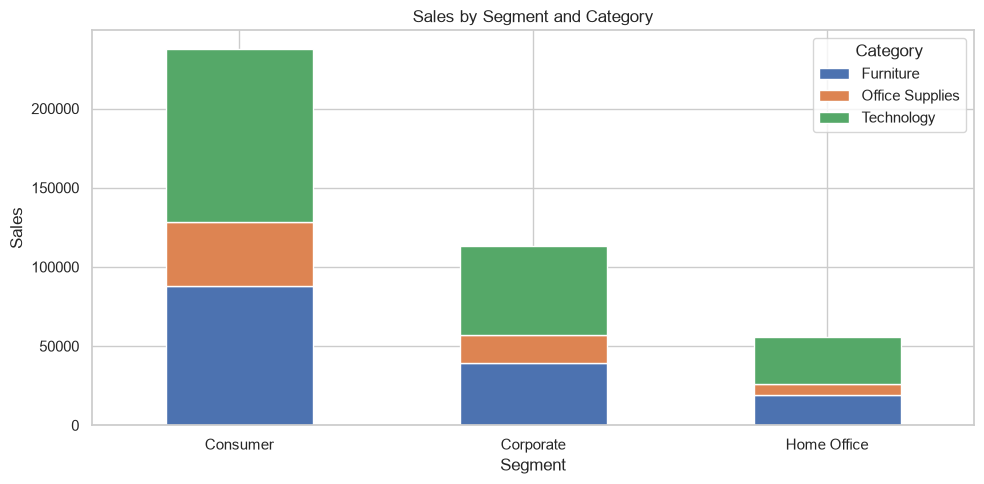

,Category,Sales,Profit
0,Furniture,146574.21,11710.69
1,Office Supplies,65284.28,5236.56
2,Technology,194347.12,13686.20


,Segment,Sales,Profit,Orders
0,Consumer,237413.30,18610.77,714
1,Corporate,113202.53,8483.49,321
2,Home Office,55589.78,3539.19,165


In [9]:
category_sales = df.groupby('Category', as_index=False).agg(Sales=('Sales','sum'), Profit=('Profit','sum'))
sns.barplot(data=category_sales, x='Category', y='Sales')
plt.title('Sales by Category')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

segment_category = df.pivot_table(index='Segment', columns='Category', values='Sales', aggfunc='sum', fill_value=0)
segment_category.plot(kind='bar', stacked=True, figsize=(10, 5))
plt.title('Sales by Segment and Category')
plt.ylabel('Sales')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
display(category_sales)
display(df.groupby('Segment', as_index=False).agg(Sales=('Sales','sum'), Profit=('Profit','sum'), Orders=('Order ID','nunique')))

## 9. Discount, sales and profit relationship

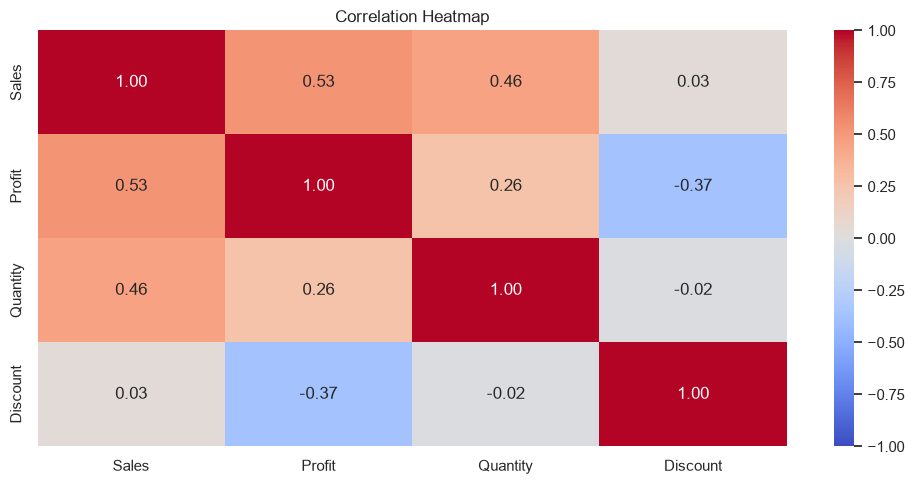

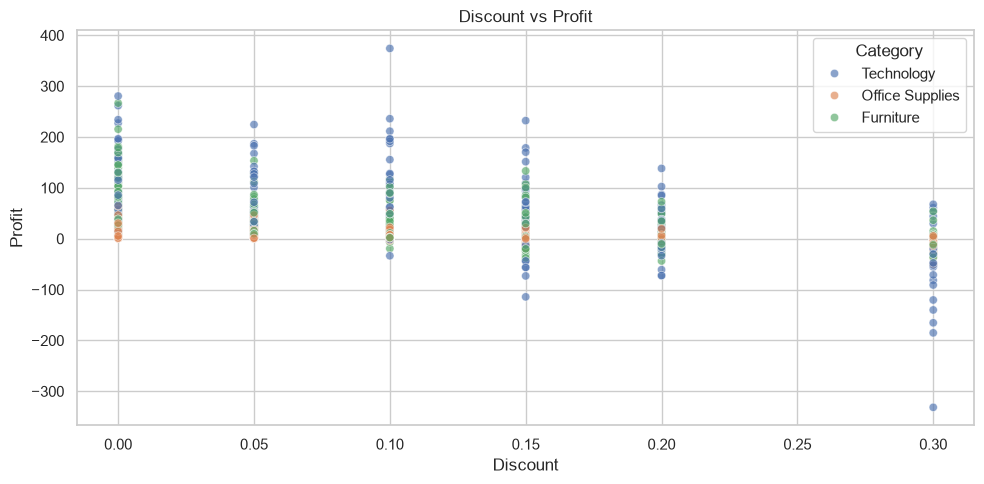

In [10]:
corr = df[['Sales', 'Profit', 'Quantity', 'Discount']].corr(numeric_only=True)
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

sns.scatterplot(data=df, x='Discount', y='Profit', hue='Category', alpha=.65)
plt.title('Discount vs Profit')
plt.tight_layout()
plt.show()

## 10. Business insights (calculated from the dataset)

In [11]:
best_month = monthly.loc[monthly['Sales'].idxmax()]
best_region = region_sales.iloc[0]
best_category = category_sales.sort_values('Sales', ascending=False).iloc[0]
best_state = state_sales.iloc[0]
print(f"Highest-sales month: {best_month['Year-Month']} (${best_month['Sales']:,.2f})")
print(f"Top region by sales: {best_region['Region']} (${best_region['Sales']:,.2f})")
print(f"Top category by sales: {best_category['Category']} (${best_category['Sales']:,.2f})")
print(f"Top state by sales: {best_state['State']} (${best_state['Sales']:,.2f})")
print(f"Overall profit margin: {profit_margin:.2f}%")

print('\nRecommendations to validate with business owners:')
print('1. Investigate top-performing months and plan inventory ahead of those periods.')
print('2. Compare profit margin—not just revenue—before prioritizing categories or regions.')
print('3. Review high-discount transactions to see whether discounts are associated with lower profit.')
print('4. Explore underperforming states and customer segments for targeted campaigns.')

Highest-sales month: 2020-09 ($21,800.50)
Top region by sales: West ($127,762.78)
Top category by sales: Technology ($194,347.12)
Top state by sales: Washington ($33,734.16)
Overall profit margin: 7.54%

Recommendations to validate with business owners:
1. Investigate top-performing months and plan inventory ahead of those periods.
2. Compare profit margin—not just revenue—before prioritizing categories or regions.
3. Review high-discount transactions to see whether discounts are associated with lower profit.
4. Explore underperforming states and customer segments for targeted campaigns.


## 11. Export summary tables

In [12]:
OUT = Path('../outputs')
if not OUT.exists():
    OUT = Path('outputs')
OUT.mkdir(exist_ok=True)
monthly.to_csv(OUT / 'monthly_sales_summary.csv', index=False)
region_sales.to_csv(OUT / 'region_sales_summary.csv', index=False)
category_sales.to_csv(OUT / 'category_sales_summary.csv', index=False)
print('Summary CSV files saved to:', OUT.resolve())

Summary CSV files saved to: D:\Sales-Data-Analysis-Project\Sales-Data-Analysis\notebooks\outputs
